In [1]:
import os
import numpy as np

# Chemin vers les données exportées, tableaux numpy
DATA_PATH = os.path.join('MP') 

# Récupération des noms des dossiers existants dans le répertoire MP
actions = os.listdir(DATA_PATH)

# Nombre de séquences
no_sequences = 100

# Longueur de séquence (nombre de fichiers par dossier)
sequence_length = 40

# Fonction pour créer des dossiers de 0 à no_sequences s'ils sont vides
def create_folders_if_needed(path, no_sequences):
    if not os.listdir(path):
        for i in range(no_sequences):
            os.makedirs(os.path.join(path, str(i)))

# Création des dossiers pour chaque action
for action in actions: 
    action_path = os.path.join(DATA_PATH, action)
    create_folders_if_needed(action_path, no_sequences)

print('Les dossiers ont été créés avec succès.')


Les dossiers ont été créés avec succès.


In [57]:
# Afficher la liste des actions
print("Liste des actions présentes dans les données :")
for action in actions:
    print(action)


Liste des actions présentes dans les données :
a
attention
day
e
engineer
graduate
happy
now
o
share
t
thank you
u
we
with
your


In [58]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
label_map = {label:num for num, label in enumerate(actions)}
print('hi')

hi


In [59]:
label_map

{'a': 0,
 'attention': 1,
 'day': 2,
 'e': 3,
 'engineer': 4,
 'graduate': 5,
 'happy': 6,
 'now': 7,
 'o': 8,
 'share': 9,
 't': 10,
 'thank you': 11,
 'u': 12,
 'we': 13,
 'with': 14,
 'your': 15}

In [60]:
from keras.preprocessing.sequence import pad_sequences

sequences, labels = [], []

for action in actions:
    action_path = os.path.join(DATA_PATH, action)
    if not os.path.exists(action_path):
        print(f"Attention : Le répertoire {action_path} n'existe pas.")
        continue
    
    for sequence_str in os.listdir(action_path):
        sequence_path = os.path.join(action_path, sequence_str)
        
        # Vérifier si le chemin est un répertoire
        if not os.path.isdir(sequence_path):
            continue
        
        # Récupérer la liste des fichiers numpy dans le répertoire de la séquence
        sequence_files = [file for file in os.listdir(sequence_path) if file.endswith('.npy')]
        
        # Vérifier si au moins un fichier est présent dans le répertoire
        if not sequence_files:
            print(f"Attention : Aucun fichier numpy trouvé dans {sequence_path}.")
            continue
        
        window = []
        for frame_file in sorted(sequence_files):  # Assurez-vous de trier les fichiers dans l'ordre numérique
            frame_path = os.path.join(sequence_path, frame_file)
            res = np.load(frame_path)
            window.append(res)
        
        sequences.append(window)
        labels.append(label_map[action])

# Convertir les labels en one-hot encoding
y = to_categorical(labels).astype(int)
max_length = 40
sequences_padded = pad_sequences(sequences, maxlen=max_length, padding='post', dtype='float32')
X = np.array(sequences_padded)

print('done')


done


In [61]:
X.shape

(1765, 40, 1662)

In [62]:
from sklearn.model_selection import cross_val_score, RepeatedKFold
from sklearn.model_selection import KFold
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score, average_precision_score
import numpy as np
import tensorflow as tf

# Initialiser le modèle en dehors de la boucle de validation croisée
model = Sequential()
model.add(GRU(256, input_shape=(max_length, 1662), return_sequences=True))
model.add(Dropout(0.5))
model.add(GRU(128, return_sequences=True))
model.add(Dropout(0.5))
model.add(GRU(64))
model.add(Dropout(0.5))
model.add(Dense(16, activation='softmax'))

# Compiler le modèle
optimizer = Adam(learning_rate=0.0001)
model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

# Définir la stratégie de validation croisée répétée
n_splits = 5
n_repeats = 3
rkf = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=42)

# Dictionnaire pour stocker les historiques
histories = {}

# Dictionnaires pour stocker les métriques pendant l'entraînement
train_metrics = {'precision': [], 'recall': [], 'accuracy': [], 'f1': []}
val_metrics = {'precision': [], 'recall': [], 'accuracy': [], 'f1': [], 'mAP': []}


# Définir la fonction de rappel pour mAP
class MAPCallback(tf.keras.callbacks.Callback):
    def __init__(self, validation_data):
        super(MAPCallback, self).__init__()
        self.validation_data = validation_data

    def on_epoch_end(self, epoch, logs=None):
        X_val, y_val = self.validation_data
        y_pred = self.model.predict(X_val)
        y_pred_classes = np.argmax(y_pred, axis=1)
        y_true_classes = np.argmax(y_val, axis=1)
        map_score = average_precision_score(y_val, y_pred, average='micro')
        print(f'\nmAP: {map_score:.4f}')
        logs['mAP'] = map_score


# Train and evaluate the model using cross-validation
for fold, (train_indices, val_indices) in enumerate(rkf.split(X, y), 1):
    print(f'Fold {fold}:')

    X_train_fold, X_val_fold = X[train_indices], X[val_indices]
    y_train_fold, y_val_fold = y[train_indices], y[val_indices]

    # Réinitialiser les poids du modèle à chaque itération
    model.reset_states()

    # Entraîner le modèle
    early_stopping = EarlyStopping(patience=70, restore_best_weights=True)
    map_callback = MAPCallback(validation_data=(X_val_fold, y_val_fold))
    history = model.fit(X_train_fold, y_train_fold, batch_size=64, epochs=500,
                        validation_data=(X_val_fold, y_val_fold), callbacks=[early_stopping, map_callback])

     # Sauvegarder les métriques d'entraînement
    train_metrics['precision'].append(history.history.get('precision'))
    train_metrics['recall'].append(history.history.get('recall'))
    train_metrics['accuracy'].append(history.history.get('accuracy'))
    train_metrics['f1'].append(history.history.get('f1'))
    histories[fold] = history


    # Évaluer le modèle sur l'ensemble de validation
    loss, accuracy = model.evaluate(X_val_fold, y_val_fold, verbose=0)
    y_pred_val = model.predict(X_val_fold)
    y_pred_val_classes = np.argmax(y_pred_val, axis=1)
    y_val_classes = np.argmax(y_val_fold, axis=1)
    precision = precision_score(y_val_classes, y_pred_val_classes, average='micro')
    recall = recall_score(y_val_classes, y_pred_val_classes, average='micro')
    f1 = f1_score(y_val_classes, y_pred_val_classes, average='micro')
    map_score = average_precision_score(y_val_fold, y_pred_val, average='micro')


    print(f'Validation Loss: {loss:.4f}, Validation Accuracy: {accuracy:.4f}')
    print(f'Validation Precision: {precision:.4f}, Validation Recall: {recall:.4f}, Validation F1-score: {f1:.4f}, Validation mAP: {map_score:.4f}')

    # Sauvegarder les métriques de validation
    val_metrics['precision'].append(precision)
    val_metrics['recall'].append(recall)
    val_metrics['accuracy'].append(accuracy)
    val_metrics['f1'].append(f1)
    val_metrics['mAP'].append(map_score)

print(" ** "*30)

# Évaluer le modèle sur l'ensemble de test
loss, accuracy = model.evaluate(X, y, verbose=0)
print(f'Overall Test Loss: {loss:.4f}, Overall Test Accuracy: {accuracy:.4f}')

Fold 1:
Epoch 1/500
23/23 [==============================] - ETA: 0s - loss: 2.8411 - accuracy: 0.0673
mAP: 0.1084
23/23 [==============================] - 78s 3s/step - loss: 2.8411 - accuracy: 0.0673 - val_loss: 2.6978 - val_accuracy: 0.1558 - mAP: 0.1084
Epoch 2/500
23/23 [==============================] - ETA: 0s - loss: 2.7631 - accuracy: 0.0857
mAP: 0.1845
23/23 [==============================] - 60s 3s/step - loss: 2.7631 - accuracy: 0.0857 - val_loss: 2.6020 - val_accuracy: 0.2181 - mAP: 0.1845
Epoch 3/500
23/23 [==============================] - ETA: 0s - loss: 2.6711 - accuracy: 0.1310
mAP: 0.1892
23/23 [==============================] - 58s 3s/step - loss: 2.6711 - accuracy: 0.1310 - val_loss: 2.5123 - val_accuracy: 0.2521 - mAP: 0.1892
Epoch 4/500
23/23 [==============================] - ETA: 0s - loss: 2.5965 - accuracy: 0.1480
mAP: 0.2178
23/23 [==============================] - 57s 3s/step - loss: 2.5965 - accuracy: 0.1480 - val_loss: 2.4396 - val_accuracy: 0.2521 - mAP:

In [65]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Évaluer le modèle sur l'ensemble de test
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Overall Test Loss: {loss:.4f}, Overall Test Accuracy: {accuracy:.4f}')

Overall Test Loss: 0.0757, Overall Test Accuracy: 0.9688


In [63]:
model.save('GRUF2.h5')

In [64]:
model.load_weights('GRUF2.h5')

print('done')

done


In [66]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score, average_precision_score, confusion_matrix, precision_recall_curve
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
import seaborn as sns

# Diviser les données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Charger le modèle entraîné
model = load_model('GRUF2.h5')

# Effectuer des prédictions sur les données de test
y_pred = model.predict(X_test)

# Convertir les prédictions en classes (par exemple, seuillage à 0.5 pour la classification binaire)
y_pred_classes = np.argmax(y_pred, axis=1)

# Convertir les étiquettes de vérité terrain en classes (si nécessaire)
y_test_classes = np.argmax(y_test, axis=1)

# Calculer la précision
precision = precision_score(y_test_classes, y_pred_classes, average='micro')

# Calculer le rappel
recall = recall_score(y_test_classes, y_pred_classes, average='micro')

# Calculer l'exactitude
accuracy = accuracy_score(y_test_classes, y_pred_classes)

# Calculer le F1-score
f1 = f1_score(y_test_classes, y_pred_classes, average='micro')

# Calculer la moyenne de la précision moyenne (MAP)
average_precision = average_precision_score(y_test, y_pred)

# Afficher les résultats
print("Précision:", precision)
print("Rappel:", recall)
print("Exactitude:", accuracy)
print("F1-score:", f1)
print("Moyenne de la précision moyenne (MAP):", average_precision)




Précision: 0.9688385269121813
Rappel: 0.9688385269121813
Exactitude: 0.9688385269121813
F1-score: 0.9688385269121813
Moyenne de la précision moyenne (MAP): 0.9948283789762382


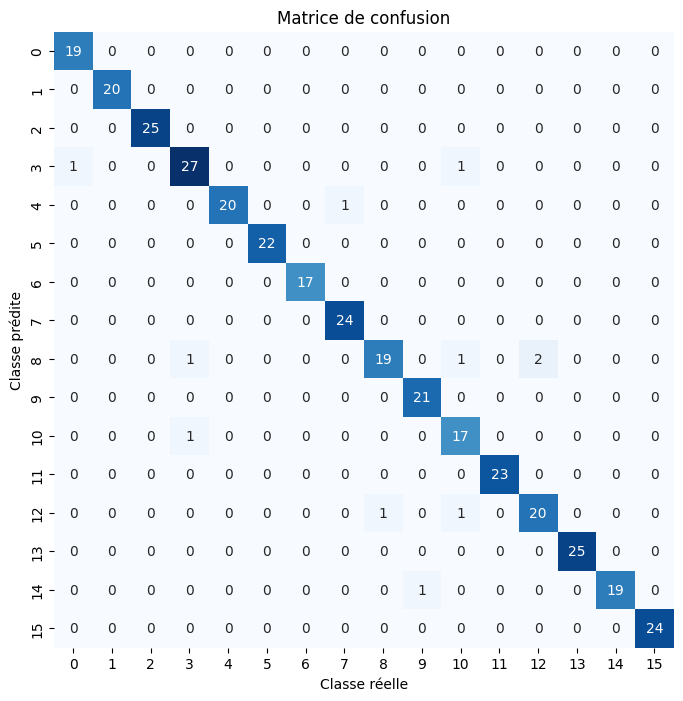

In [67]:
# Calculer la matrice de confusion
conf_matrix = confusion_matrix(y_test_classes, y_pred_classes)

# Afficher la matrice de confusion avec seaborn
plt.figure(figsize=(8, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Classe réelle')
plt.ylabel('Classe prédite')
plt.title('Matrice de confusion')
plt.show()


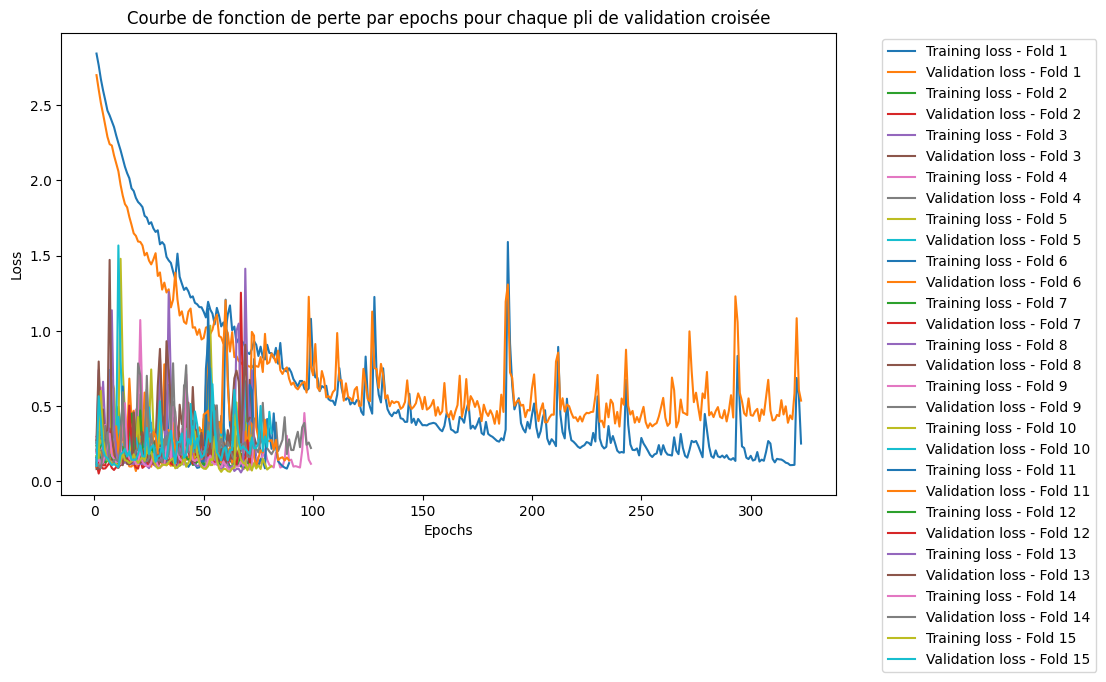

In [68]:
# Tracer le diagramme de la fonction de perte pour chaque pli
plt.figure(figsize=(10, 6))
for fold, history in histories.items():
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(loss) + 1)
    plt.plot(epochs, loss, label=f'Training loss - Fold {fold}')
    plt.plot(epochs, val_loss, label=f'Validation loss - Fold {fold}')

plt.title('Courbe de fonction de perte par epochs pour chaque pli de validation croisée')
plt.xlabel('Epochs')
plt.ylabel('Loss')

# Afficher la légende en dehors du tracé
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


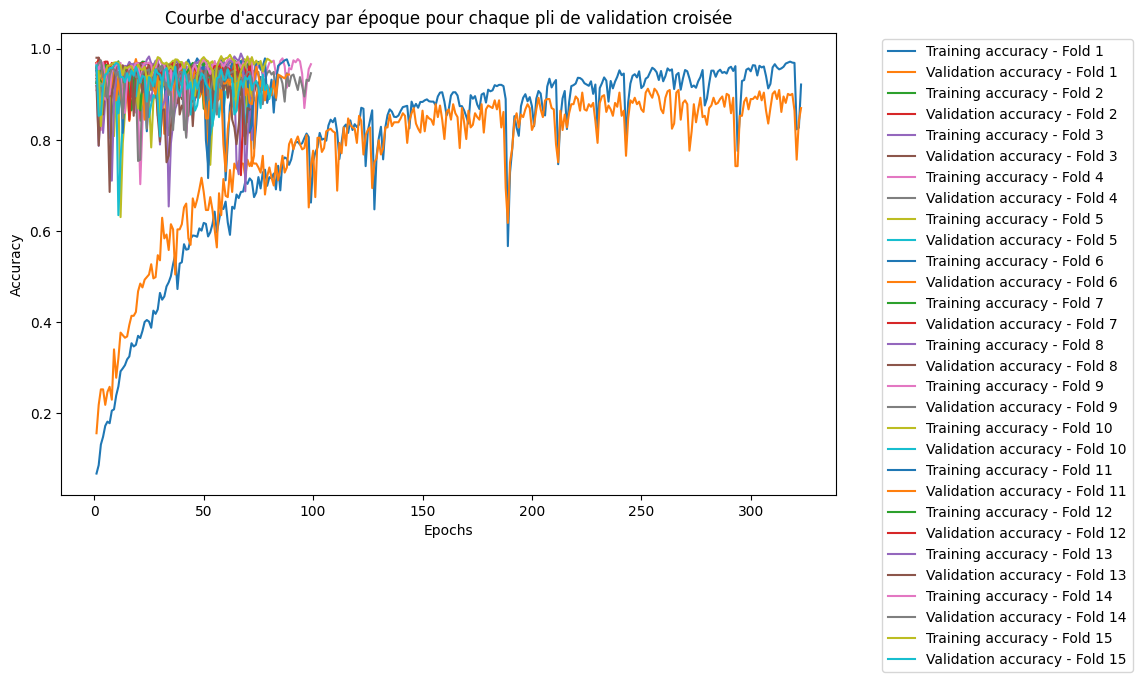

In [69]:
# Tracer le diagramme de précision pour chaque pli
plt.figure(figsize=(10, 6))
for fold, history in histories.items():
    accuracy = history.history['accuracy']
    val_accuracy = history.history['val_accuracy']
    
    # Vérifier si les longueurs sont différentes
    if len(accuracy) != len(val_accuracy):
        # Ajuster la longueur de la liste la plus courte
        min_length = min(len(accuracy), len(val_accuracy))
        accuracy = accuracy[:min_length]
        val_accuracy = val_accuracy[:min_length]
        
    epochs = range(1, len(accuracy) + 1)
    plt.plot(epochs, accuracy, label=f'Training accuracy - Fold {fold}')
    plt.plot(epochs, val_accuracy, label=f'Validation accuracy - Fold {fold}')

plt.title('Courbe d\'accuracy par époque pour chaque pli de validation croisée')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

# Afficher la légende en dehors du tracé
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


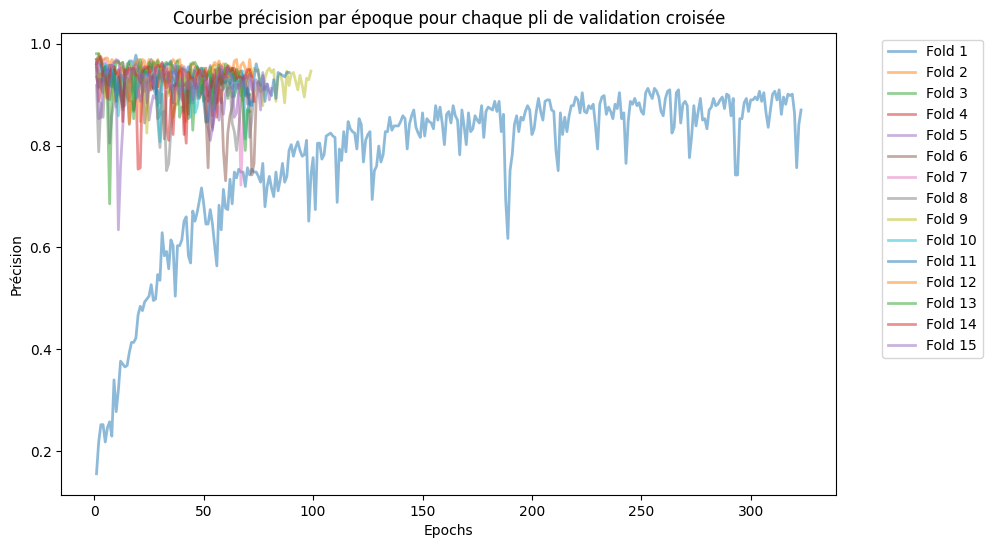

In [70]:
plt.figure(figsize=(10, 6))
for fold, history in histories.items():
    accuracy = history.history['accuracy']
    val_accuracy = history.history['val_accuracy']
    
    # Vérifier si les longueurs sont différentes
    if len(accuracy) != len(val_accuracy):
        # Ajuster la longueur de la liste la plus courte
        min_length = min(len(accuracy), len(val_accuracy))
        accuracy = accuracy[:min_length]
        val_accuracy = val_accuracy[:min_length]
        
    epochs = range(1, len(accuracy) + 1)
    # plt.plot(epochs, accuracy, linestyle='-', linewidth=2, label=f'Training accuracy - Fold {fold}')
    plt.plot(epochs, val_accuracy, linestyle='-', linewidth=2, label=f'Fold {fold}', alpha=0.5)

plt.title('Courbe précision par époque pour chaque pli de validation croisée')
plt.xlabel('Epochs')
plt.ylabel('Précision')

# Afficher la légende en dehors du tracé
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


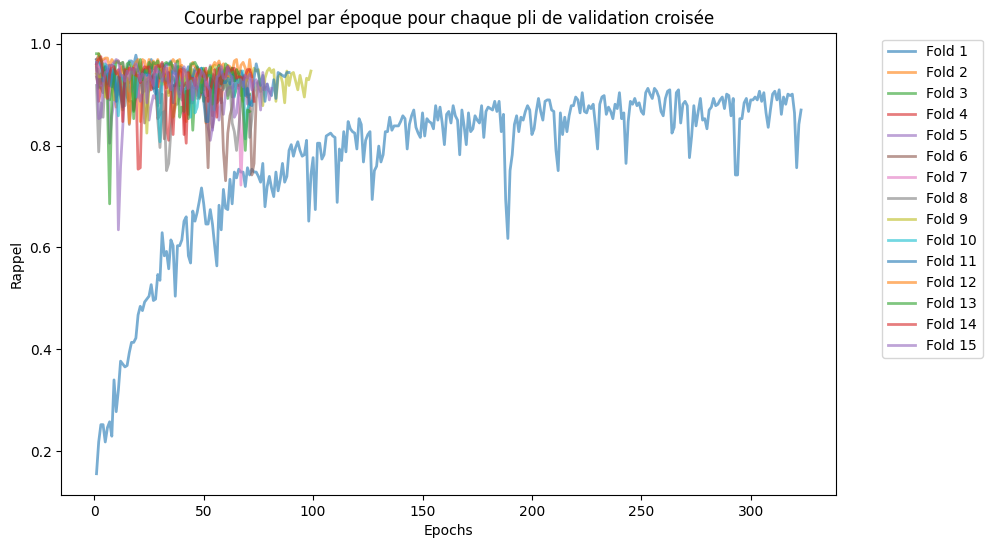

In [72]:
plt.figure(figsize=(10, 6))
for fold, history in histories.items():
    accuracy = history.history['accuracy']
    val_accuracy = history.history['val_accuracy']
    
    # Vérifier si les longueurs sont différentes
    if len(accuracy) != len(val_accuracy):
        # Ajuster la longueur de la liste la plus courte
        min_length = min(len(accuracy), len(val_accuracy))
        accuracy = accuracy[:min_length]
        val_accuracy = val_accuracy[:min_length]
        
    epochs = range(1, len(accuracy) + 1)
    # plt.plot(epochs, accuracy, linestyle='-', linewidth=2, label=f'Training accuracy - Fold {fold}')
    plt.plot(epochs, val_accuracy, linestyle='-', linewidth=2, label=f'Fold {fold}', alpha=0.6)

plt.title('Courbe rappel par époque pour chaque pli de validation croisée')
plt.xlabel('Epochs')
plt.ylabel('Rappel')

# Afficher la légende en dehors du tracé
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


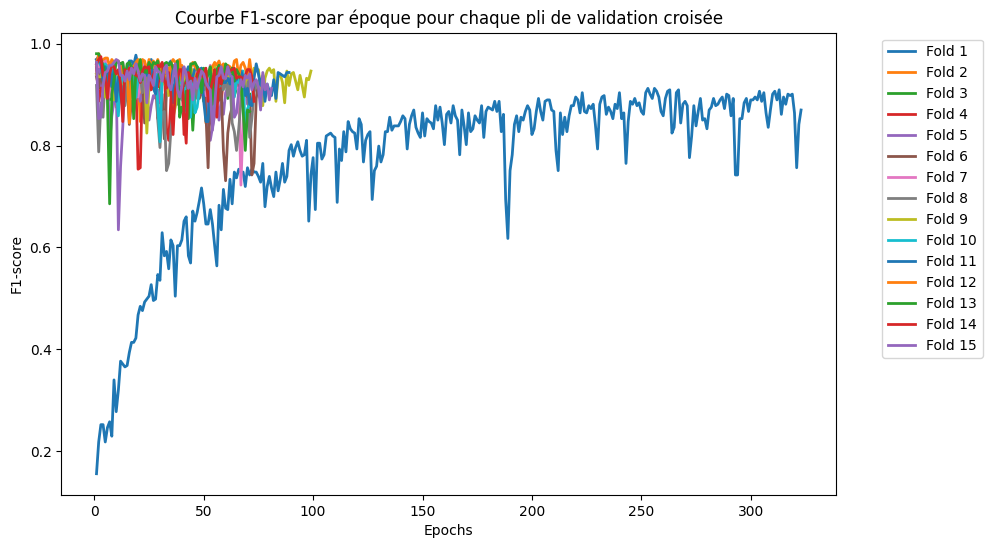

In [73]:
plt.figure(figsize=(10, 6))
for fold, history in histories.items():
    accuracy = history.history['accuracy']
    val_accuracy = history.history['val_accuracy']
    
    # Vérifier si les longueurs sont différentes
    if len(accuracy) != len(val_accuracy):
        # Ajuster la longueur de la liste la plus courte
        min_length = min(len(accuracy), len(val_accuracy))
        accuracy = accuracy[:min_length]
        val_accuracy = val_accuracy[:min_length]
        
    epochs = range(1, len(accuracy) + 1)
    # plt.plot(epochs, accuracy, linestyle='-', linewidth=2, label=f'Training accuracy - Fold {fold}')
    plt.plot(epochs, val_accuracy, linestyle='-', linewidth=2, label=f'Fold {fold}', alpha=1)
  


plt.title('Courbe F1-score par époque pour chaque pli de validation croisée')
plt.xlabel('Epochs')
plt.ylabel('F1-score')

# Afficher la légende en dehors du tracé
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


           Classe Précision    Rappel  F1-score  Exactitude  \
0               a      0.95       1.0  0.974359         NaN   
1       attention       1.0       1.0       1.0         NaN   
2             day       1.0       1.0       1.0         NaN   
3               e  0.931034  0.931034  0.931034         NaN   
4        engineer       1.0  0.952381   0.97561         NaN   
5        graduate       1.0       1.0       1.0         NaN   
6           happy       1.0       1.0       1.0         NaN   
7             now      0.96       1.0  0.979592         NaN   
8               o      0.95  0.826087  0.883721         NaN   
9           share  0.954545       1.0  0.976744         NaN   
10              t      0.85  0.944444  0.894737         NaN   
11      thank you       1.0       1.0       1.0         NaN   
12              u  0.909091  0.909091  0.909091         NaN   
13             we       1.0       1.0       1.0         NaN   
14           with       1.0      0.95  0.974359        

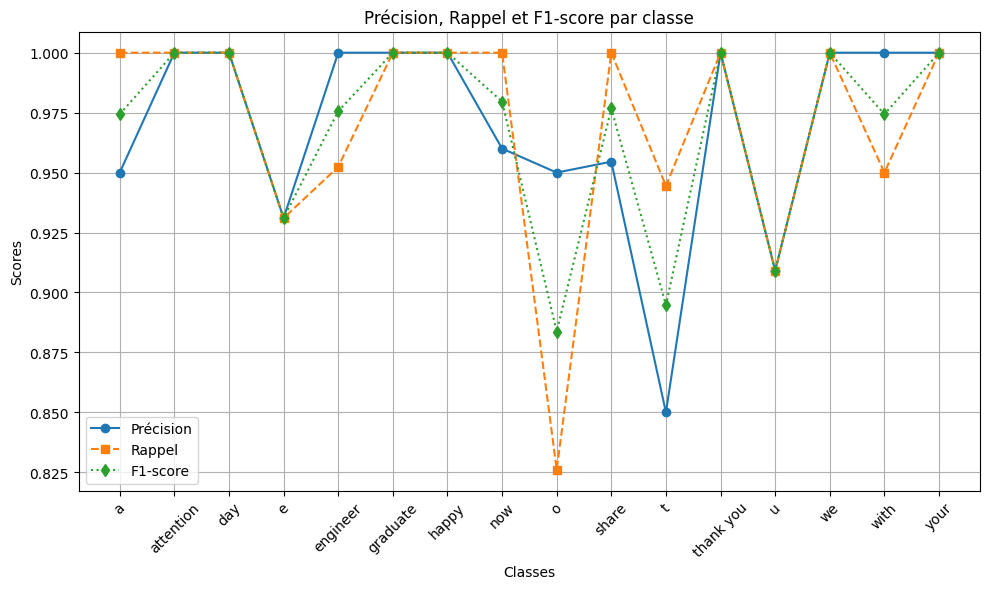

In [74]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, average_precision_score
from tensorflow.keras.models import load_model
import time
import matplotlib.pyplot as plt

# Supposez que vous avez les étiquettes de vos données
labels = actions

# Encoder les étiquettes
label_encoder = LabelEncoder()
label_encoder.fit(labels)

# Exemple de récupération des noms de classes (assurez-vous que les étiquettes d'origine sont disponibles)
class_names = label_encoder.classes_

# Diviser les données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



# Effectuer des prédictions sur les données de test et mesurer le temps d'inférence
start_time = time.time()
y_pred = model.predict(X_test)
inference_time = time.time() - start_time

# Convertir les prédictions en classes (par exemple, seuillage à 0.5 pour la classification binaire)
y_pred_classes = np.argmax(y_pred, axis=1)

# Convertir les étiquettes de vérité terrain en classes (si nécessaire)
y_test_classes = np.argmax(y_test, axis=1)

# Calculer la précision, le rappel et le F1-score pour chaque classe
precision_per_class = precision_score(y_test_classes, y_pred_classes, average=None)
recall_per_class = recall_score(y_test_classes, y_pred_classes, average=None)
f1_per_class = f1_score(y_test_classes, y_pred_classes, average=None)

# Calculer la précision globale (micro-average)
precision_micro = precision_score(y_test_classes, y_pred_classes, average='micro')

# Calculer le rappel global (micro-average)
recall_micro = recall_score(y_test_classes, y_pred_classes, average='micro')

# Calculer l'exactitude
accuracy = accuracy_score(y_test_classes, y_pred_classes)

# Calculer la moyenne de la précision moyenne (MAP)
average_precision = average_precision_score(y_test, y_pred, average='macro')

# Construire le tableau des résultats
results = {
    "Classe": list(class_names) + ["Micro-average", "Global"],
    "Précision": np.append(precision_per_class, [precision_micro, None]),
    "Rappel": np.append(recall_per_class, [recall_micro, None]),
    "F1-score": np.append(f1_per_class, [None, None]),
    "Exactitude": [None] * len(precision_per_class) + [None, accuracy],
    "Temps d'inférence (s)": [None] * len(precision_per_class) + [None, inference_time],
    "MAP": [None] * len(precision_per_class) + [None, average_precision]
}

# Créer un DataFrame Pandas pour un affichage structuré
results_df = pd.DataFrame(results)

# Afficher les résultats
print(results_df)

# Tracer les courbes de précision, rappel et F1-score
plt.figure(figsize=(10, 6))
classes = np.arange(len(class_names))

plt.plot(classes, precision_per_class, marker='o', linestyle='-', label='Précision')
plt.plot(classes, recall_per_class, marker='s', linestyle='--', label='Rappel')
plt.plot(classes, f1_per_class, marker='d', linestyle=':', label='F1-score')

plt.xticks(classes, class_names, rotation=45)
plt.xlabel('Classes')
plt.ylabel('Scores')
plt.title('Précision, Rappel et F1-score par classe')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [75]:
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import load_model
import time


# Effectuer des prédictions sur un petit échantillon de données pour mesurer le temps d'inférence
sample_size = 100  # Taille de l'échantillon pour les prédictions
X_sample = X_test[:sample_size]  # Sélectionner un petit sous-ensemble de données de test

start_time = time.time()  # Mesurer le temps de début

# Effectuer des prédictions sur l'échantillon
y_pred = model.predict(X_sample)

end_time = time.time()  # Mesurer le temps de fin

# Calculer le temps moyen par inférence
inference_time_per_sample = (end_time - start_time) / sample_size

print("Temps moyen par inférence:", inference_time_per_sample, "secondes par échantillon")


Temps moyen par inférence: 0.007151534557342529 secondes par échantillon


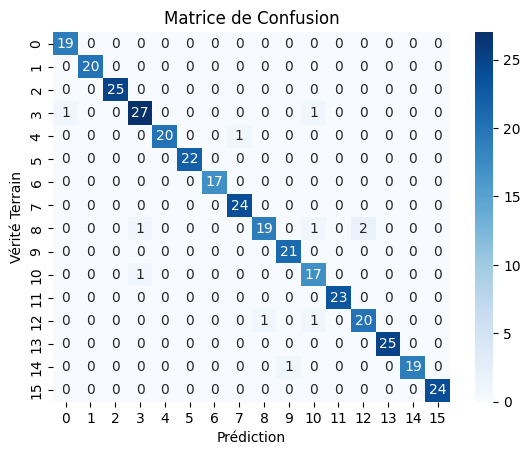

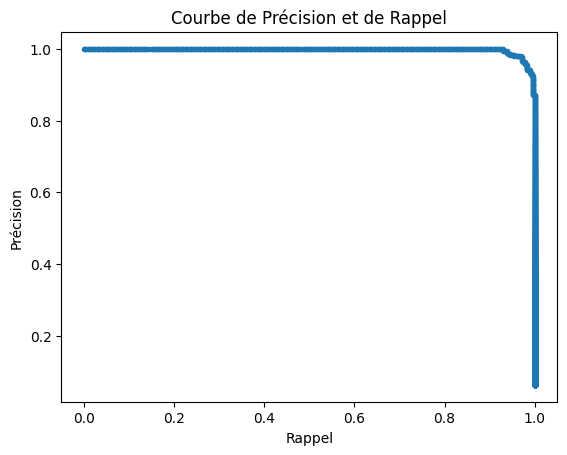

C:\Users\ENVY\AppData\Local\Programs\Python\Python39\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\ENVY\AppData\Local\Programs\Python\Python39\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


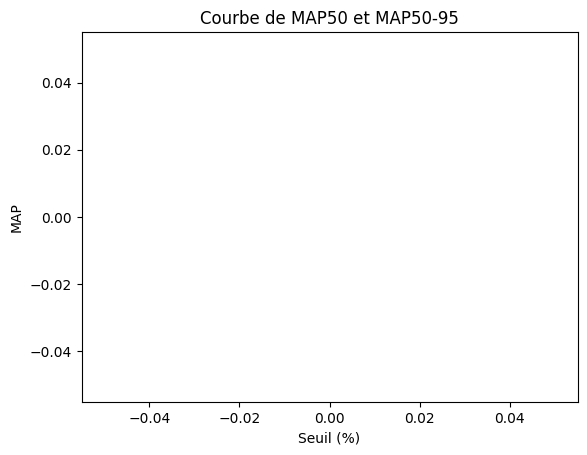

Précision: 0.9688385269121813
Rappel: 0.9688385269121813
Exactitude: 0.9688385269121813
Moyenne de la précision moyenne (MAP): 0.9948283789762382


In [76]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_recall_curve, auc, average_precision_score
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import History

# Charger les données (assurez-vous que X et y sont définis)
# X, y = ...

# Diviser les données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Charger le modèle et effectuer des prédictions
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

# 1. Matrice de confusion
cm = confusion_matrix(y_test_classes, y_pred_classes)
plt.figure()
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de Confusion')
plt.xlabel('Prédiction')
plt.ylabel('Vérité Terrain')
plt.show()

# 2. Courbe de précision et de rappel
precision, recall, _ = precision_recall_curve(y_test.ravel(), y_pred.ravel())
plt.figure()
plt.plot(recall, precision, marker='.')
plt.title('Courbe de Précision et de Rappel')
plt.xlabel('Rappel')
plt.ylabel('Précision')
plt.show()

# 3. Courbe de MAP50 et MAP50-95 (en utilisant une fonction personnalisée)
def calculate_map(pred_scores, y_true, threshold_low=0.5, threshold_high=0.95):
    selected_indices = np.where((pred_scores >= threshold_low) & (pred_scores <= threshold_high))[0]
    selected_y_true = y_true[selected_indices]
    selected_y_pred = pred_scores[selected_indices]

    map_scores = []
    for i in range(len(selected_y_true)):
        ap = average_precision_score(selected_y_true[i], selected_y_pred[i])
        map_scores.append(ap)

    map_average = np.mean(map_scores)
    return map_average

# Calcul de MAP50
map50 = calculate_map(y_pred[:, 1], y_test, threshold_low=0.5)

# Calcul de MAP50-95
map50_95 = calculate_map(y_pred[:, 1], y_test, threshold_low=0.5, threshold_high=0.95)

plt.figure()
plt.plot([50, 95], [map50, map50_95], marker='o')
plt.title('Courbe de MAP50 et MAP50-95')
plt.xlabel('Seuil (%)')
plt.ylabel('MAP')
plt.show()

# 4. Courbe de la fonction de perte (sans historique)
# Note: Vous devez avoir l'historique d'entraînement pour tracer cette courbe

# 5. Affichage des métriques
precision = precision_score(y_test_classes, y_pred_classes, average='micro')
recall = recall_score(y_test_classes, y_pred_classes, average='micro')
accuracy = accuracy_score(y_test_classes, y_pred_classes)
average_precision = average_precision_score(y_test, y_pred)

print("Précision:", precision)
print("Rappel:", recall)
print("Exactitude:", accuracy)
print("Moyenne de la précision moyenne (MAP):", average_precision)


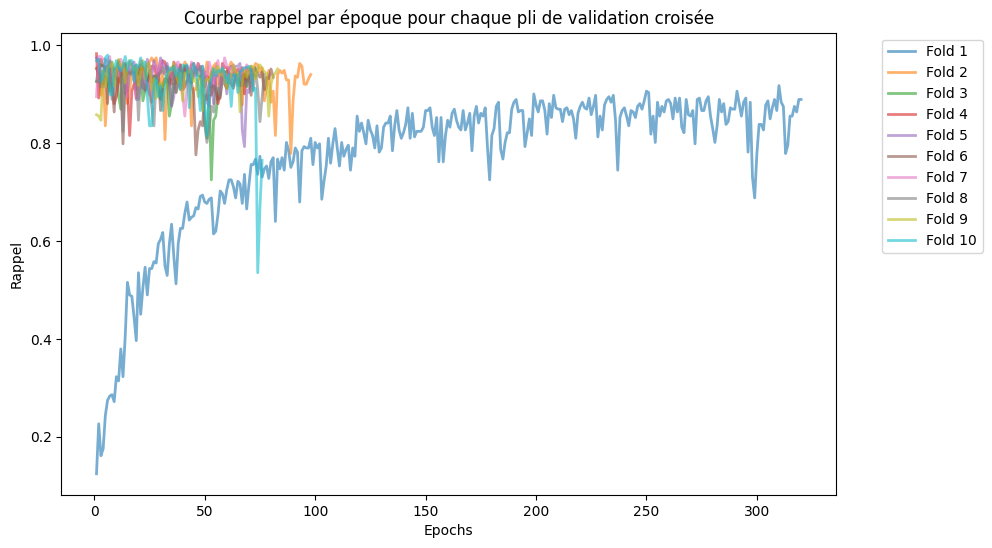

In [50]:
plt.figure(figsize=(10, 6))
for fold, history in histories.items():
    accuracy = history.history['accuracy']
    val_accuracy = history.history['val_accuracy']
    
    # Vérifier si les longueurs sont différentes
    if len(accuracy) != len(val_accuracy):
        # Ajuster la longueur de la liste la plus courte
        min_length = min(len(accuracy), len(val_accuracy))
        accuracy = accuracy[:min_length]
        val_accuracy = val_accuracy[:min_length]
        
    epochs = range(1, len(accuracy) + 1)
    # plt.plot(epochs, accuracy, linestyle='-', linewidth=2, label=f'Training accuracy - Fold {fold}')
    plt.plot(epochs, val_accuracy, linestyle='-', linewidth=2, label=f'Fold {fold}', alpha=0.6)

plt.title('Courbe rappel par époque pour chaque pli de validation croisée')
plt.xlabel('Epochs')
plt.ylabel('Rappel')

# Afficher la légende en dehors du tracé
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


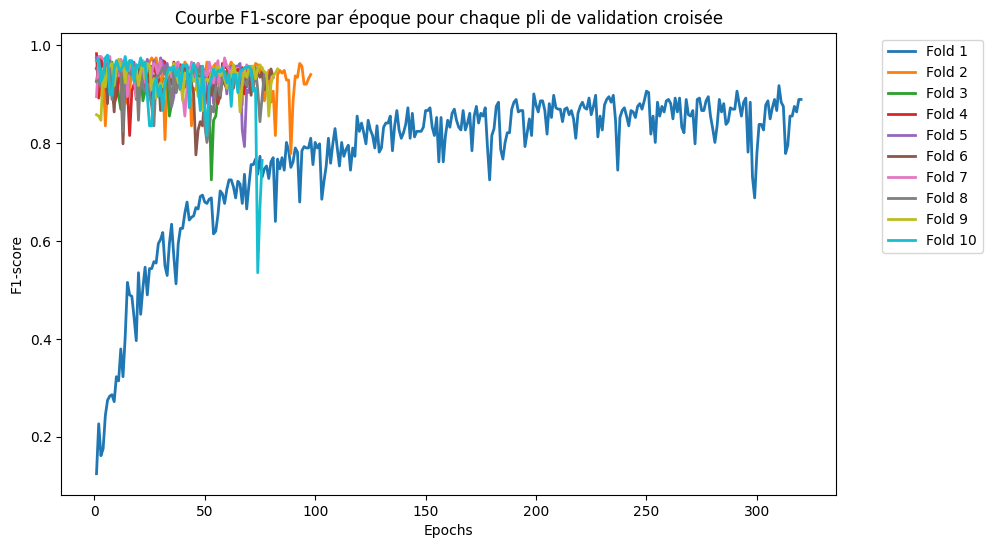

In [51]:
plt.figure(figsize=(10, 6))
for fold, history in histories.items():
    accuracy = history.history['accuracy']
    val_accuracy = history.history['val_accuracy']
    
    # Vérifier si les longueurs sont différentes
    if len(accuracy) != len(val_accuracy):
        # Ajuster la longueur de la liste la plus courte
        min_length = min(len(accuracy), len(val_accuracy))
        accuracy = accuracy[:min_length]
        val_accuracy = val_accuracy[:min_length]
        
    epochs = range(1, len(accuracy) + 1)
    # plt.plot(epochs, accuracy, linestyle='-', linewidth=2, label=f'Training accuracy - Fold {fold}')
    plt.plot(epochs, val_accuracy, linestyle='-', linewidth=2, label=f'Fold {fold}', alpha=1)

plt.title('Courbe F1-score par époque pour chaque pli de validation croisée')
plt.xlabel('Epochs')
plt.ylabel('F1-score')

# Afficher la légende en dehors du tracé
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


In [65]:
import numpy as np

# Assurez-vous que y_train est correctement chargé et qu'il contient les étiquettes de classe
# Affichez quelques exemples pour vérifier la structure des données
print("y_train shape:", y_train.shape)
print("Exemples de y_train:", y_train[:10])

# Compter le nombre d'exemples pour chaque classe dans y_train
classes, counts = np.unique(y_train, return_counts=True)

# Afficher les valeurs uniques et leurs fréquences
print("Classes uniques:", classes)
print("Nombre d'exemples par classe:", counts)


y_train shape: (974, 11)
Exemples de y_train: [[0 0 0 1 0 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 1 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 0 0 0]
 [0 0 0 0 0 1 0 0 0 0 0]]
Classes uniques: [0 1]
Nombre d'exemples par classe: [9740  974]


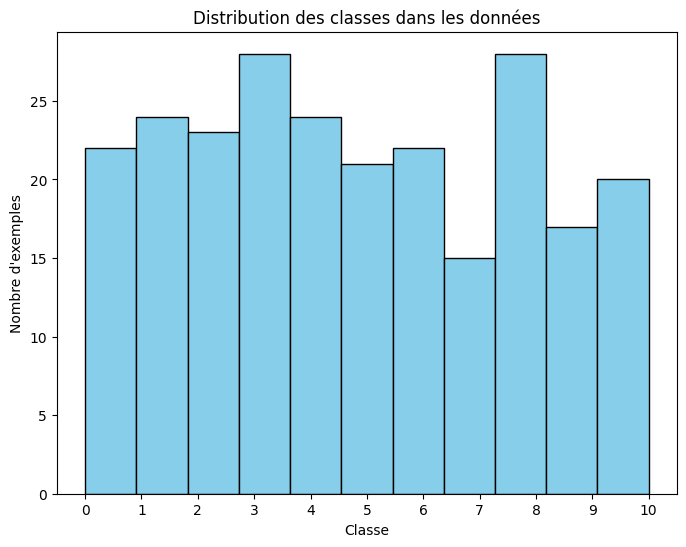

Matrice de confusion :
 [[22  0  0  0  0  0  0  0  0  0  0]
 [ 0 24  0  0  0  0  0  0  0  0  0]
 [ 0  0 23  0  0  0  0  0  0  0  0]
 [ 0  0  0 28  0  0  0  0  0  0  0]
 [ 0  0  0  0 24  0  0  0  0  0  0]
 [ 0  0  0  0  0 21  0  0  0  0  0]
 [ 0  0  0  0  0  0 21  0  0  1  0]
 [ 0  0  0  0  0  0  0 15  0  0  0]
 [ 0  0  0  0  0  0  0  0 28  0  0]
 [ 0  0  0  0  0  0  0  0  0 17  0]
 [ 0  0  0  0  0  0  0  0  0  0 20]]
Accuracy : 0.9959016393442623


In [66]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold

# Supposons que ytrue et yhat représentent les vraies valeurs et les prédictions de votre modèle
# ytrue = ... 
# yhat = ...

# 1. Distribution des classes
# Visualisation de la répartition des classes dans les données
plt.figure(figsize=(8, 6))
plt.hist(ytrue, bins=len(np.unique(ytrue)), color='skyblue', edgecolor='black')
plt.title('Distribution des classes dans les données')
plt.xlabel('Classe')
plt.ylabel('Nombre d\'exemples')
plt.xticks(np.arange(min(ytrue), max(ytrue)+1, 1))
plt.show()

# 2. Conséquences des erreurs de classification
# Calcul de la matrice de confusion
conf_matrix = confusion_matrix(ytrue, yhat)
print('Matrice de confusion :\n', conf_matrix)

# Calcul de l'accuracy
accuracy = accuracy_score(ytrue, yhat)
print('Accuracy :', accuracy)

In [75]:
from sklearn.model_selection import cross_val_score, RepeatedKFold
from sklearn.model_selection import KFold
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import StratifiedKFold



# Initialiser le modèle en dehors de la boucle de validation croisée
model = Sequential()
model.add(LSTM(256, input_shape=(max_length, 1662), return_sequences=True))
model.add(Dropout(0.5))
model.add(LSTM(128, return_sequences=True))
model.add(Dropout(0.5))
model.add(LSTM(64))
model.add(Dropout(0.5))
model.add(Dense(11, activation='softmax'))

# Compiler le modèle
optimizer = Adam(learning_rate=0.0001)  # Réduction du taux d'apprentissage
model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

# Définir la stratégie de validation croisée répétée
n_splits = 5
n_repeats = 3
rkf = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=42)


# Train and evaluate the model using cross-validation
for fold, (train_indices, val_indices) in enumerate(rkf.split(X, y), 1):
    print(f'Fold {fold}:')

    X_train_fold, X_val_fold = X[train_indices], X[val_indices]
    y_train_fold, y_val_fold = y[train_indices], y[val_indices]

    # Réinitialiser les poids du modèle à chaque itération
    model.reset_states()

    # Entraîner le modèle
    early_stopping = EarlyStopping(patience=70, restore_best_weights=True)
    history = model.fit(X_train_fold, y_train_fold, batch_size=64, epochs=500,
                        validation_data=(X_val_fold, y_val_fold), callbacks=[early_stopping])

    # Évaluer le modèle sur l'ensemble de validation
    loss, accuracy = model.evaluate(X_val_fold, y_val_fold, verbose=0)
    print(f'Validation Loss: {loss:.4f}, Validation Accuracy: {accuracy:.4f}')

print(" ** "*30)

# Évaluer le modèle sur l'ensemble de test
loss, accuracy = model.evaluate(X, y, verbose=0)
print(f'Overall Test Loss: {loss:.4f}, Overall Test Accuracy: {accuracy:.4f}')

Fold 1:
Epoch 1/500
16/16 [==============================] - 51s 2s/step - loss: 2.4353 - accuracy: 0.0862 - val_loss: 2.3967 - val_accuracy: 0.1107
Epoch 2/500
16/16 [==============================] - 34s 2s/step - loss: 2.4144 - accuracy: 0.0893 - val_loss: 2.3666 - val_accuracy: 0.2008
Epoch 3/500
16/16 [==============================] - 34s 2s/step - loss: 2.3495 - accuracy: 0.1407 - val_loss: 2.3024 - val_accuracy: 0.2377
Epoch 4/500
16/16 [==============================] - 34s 2s/step - loss: 2.2657 - accuracy: 0.1930 - val_loss: 2.1552 - val_accuracy: 0.2049
Epoch 5/500
16/16 [==============================] - 33s 2s/step - loss: 2.1900 - accuracy: 0.1910 - val_loss: 2.0353 - val_accuracy: 0.2459
Epoch 6/500
16/16 [==============================] - 33s 2s/step - loss: 2.0677 - accuracy: 0.2361 - val_loss: 1.8903 - val_accuracy: 0.4057
Epoch 7/500
16/16 [==============================] - 33s 2s/step - loss: 1.9541 - accuracy: 0.3142 - val_loss: 1.7762 - val_accuracy: 0.4098
Epoch

In [76]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Évaluer le modèle sur l'ensemble de test
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Overall Test Loss: {loss:.4f}, Overall Test Accuracy: {accuracy:.4f}')

Overall Test Loss: 0.0044, Overall Test Accuracy: 1.0000
